# **IMPORTS**

In [ ]:
# data acquisition
!pip install -q ee wxee

# data preprocessing
!pip install -q rasterio scipy

In [ ]:
import torch
import numpy as np

import ee
import wxee
from torch.utils.data import IterableDataset, DataLoader

import torch.nn.functional as F
import math

import matplotlib.pyplot as plt

# initialize Google Earth Engine
ee.Authenticate()
from google.colab import userdata
ee.Initialize(project=userdata.get('EAI_project_ID'))

# **DATA**

## Preprocessing <----------------- RICONTROLLARE

In [ ]:
class Sentinel2Preprocessor:
    def __init__(self, patch_size, num_bands, stride=None, scale_factor=None):
        self.patch_size = patch_size    # square patch dimensions
        self.num_bands = num_bands    # number of spectral bands (C)
        self.stride = stride if stride is not None else patch_size    # stride for patch extraction, defaults to patch_size (non-overlapping)
        self.scale_factor = scale_factor    # resize input images before patching
        # CONTROLLARE QUANDO E COME VA FATTO IL RESAMPLING (ERA NECESSARIO PER APPLICARE 1D DCT.. (gemini))

        # pre-compute the DCT matrix to speed up processing
        self.dct_matrix = self._create_dct_matrix(num_bands)    # (C, C) matrix

    def _create_dct_matrix(self, N):
        # Generate the standard Type-II DCT matrix
        # DCT output Y = M * X (where X is the spectral signature vector)

        # Create grid for k (rows) and n (columns)
        k = torch.arange(N).unsqueeze(1).float()  # (N, 1)
        n = torch.arange(N).unsqueeze(0).float()  # (1, N)

        # DCT-II formula
        matrix = torch.cos((math.pi / N) * (n + 0.5) * k)

        # Orthonormalization coefficients
        # k=0 gets 1/sqrt(N), k>0 gets sqrt(2/N)
        norm_coeffs = torch.ones(N, 1) * math.sqrt(2 / N)
        norm_coeffs[0, 0] = 1 / math.sqrt(N)

        return matrix * norm_coeffs

    def apply_dct(self, patches):
        # apply 1D DCT to the Channel dimension (dim 1)
        # Input shape: (Batch, Channels, Height, Width)

        # move Channels to the last dimension for Matrix Mul
        patches_permuted = patches.permute(0, 2, 3, 1)    # (Batch, H, W, C)

        # apply Matrix Multiplication: Y = X @ M.T
        # use the pre-calculated self.dct_matrix
        dct_patches = torch.matmul(patches_permuted, self.dct_matrix.t())

        # permute back to (Batch, Channels, H, W)
        return dct_patches.permute(0, 3, 1, 2)

    def __call__(self, img_tensor):
        C, H, W = img_tensor.shape

        # --------------- Resampling (Optional)
        if self.scale_factor:
            img_tensor = F.interpolate(
                img_tensor.unsqueeze(0),
                scale_factor=self.scale_factor,
                mode='bilinear',
                align_corners=False
            ).squeeze(0)
            C, H, W = img_tensor.shape

        # --------------- padding
        # pad image so H and W are divisible by patch_size (prevent dropping edge data)
        pad_h = (self.patch_size - (H % self.patch_size)) % self.patch_size
        pad_w = (self.patch_size - (W % self.patch_size)) % self.patch_size

        # padding format is (left, right, top, bottom)
        if pad_h > 0 or pad_w > 0:
            img_tensor = F.pad(img_tensor, (0, pad_w, 0, pad_h), mode='reflect')

        # --------------- patch Extraction
        # Add batch dim: (1, C, H, W)
        img_tensor = img_tensor.unsqueeze(0)

        # Extract patches
        # Output of unfold is somewhat complex, requires view manipulation
        patches = img_tensor.unfold(2, self.patch_size, self.stride) \
                            .unfold(3, self.patch_size, self.stride)

        # Current shape: (1, C, H_steps, W_steps, Patch_H, Patch_W)
        # Reshape to: (Num_Patches, C, Patch_H, Patch_W)
        patches = patches.contiguous().view(-1, C, self.patch_size, self.patch_size)

        # --------------- apply DCT
        # Apply DCT to the Channel dimension of every pixel
        patches_dct = self.apply_dct(patches)

        return patches_dct    # (Num_Patches, C, Patch_Size, Patch_Size)

## Stream of Sentinel-2 data

In [ ]:
class Sentinel2Stream(IterableDataset):
    def __init__(self, rois, time_start, time_end, bands_to_use, preprocessor):
        self.rois = rois    # list of ee.Geometry.Rectangle objects (regions of interest)
        self.time_start = time_start    # string (e.g. '2020-01-01')
        self.time_end = time_end      # string (e.g. '2020-12-31')
        self.bands_to_use = bands_to_use
        self.preprocessor = preprocessor

    def stream_generator(self):
        # loop through the regions of interest
        for roi in self.rois:
            try:
                # --------------- define the image collection
                s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                      .filterBounds(roi)
                      .filterDate(self.time_start, self.time_end)
                      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))    # discard images more than 30% cloudy
                      .select(self.bands_to_use)
                      )
                # Check if collection is empty before downloading
                if s2.size().getInfo() == 0: continue

                # --------------- download the images (from the roi at the specified time interval) into the RAM
                ts = wxee.TimeSeries(s2)    # create time series
                # fetch into RAM (Lazy Loading)
                ds = ts.wx.to_xarray(region=roi, scale=10, progress=False)  # scale=10 native resolution, scale=20 reduces size

                # --------------- convert data to numpy
                # format for PyTorch (Time, Channels, Height, Width)
                data = np.stack([ds[b].values for b in self.bands_to_use], axis=1)    # stack bands

                # --------------- preprocess
                # normalize
                data = data.astype(float) / 10000.0
                data = np.nan_to_num(data)    # handle missing pixels

                timesteps = data.shape[0]   # data shape: (TimeSteps, Channels, H, W)
                for i in range(timesteps):  # iterate through all images
                    img_tensor = torch.from_numpy(data[i]).float()    # convert to tensor
                    # skip mostly black/empty images
                    if img_tensor.max() == 0 or img_tensor.mean() < 0.001: continue

                    # yield preprocessed patches
                    patches_batch = self.preprocessor(img_tensor)   # (N_patches, C, H, W)
                    for patch in patches_batch:
                      # skip mostly black/empty patches
                      if patch.max() == 0 or patch.mean() < 0.001: continue
                      yield patch

            except Exception as e:
                print(f"Skipping a ROI, error: {e}")
                continue

    def __iter__(self):
        return iter(self.stream_generator())

# **NETWORK**  <------------------------- RICONTROLLOARE

In [ ]:
class model_1():
  def __init__(self, in_channels, hidden_transformer_dimension, out_channels):
    self.in_channels = in_channels
    self.out_channels = out_channels
    self.hidden_transformer_dimension = hidden_transformer_dimension

    # first MLP
    self.mlp1 = torch.nn.Sequential(
        torch.nn.Linear(in_features=self.in_channels, out_features=128),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=128, out_features=64),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=64, out_features=32),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=32, out_features=self.out_channels)
    )
    # first linear layer (instead of the first MLP)
    self.linear1 = torch.nn.Linear(in_features=self.in_channels, out_features=self.hidden_transformer_dimension)

    # Transformer encoder
    self.transformer_encoder = torch.nn.TransformerEncoder(
        encoder_layer=torch.nn.TransformerEncoderLayer(d_model=self.hidden_transformer_dimension, nhead=6),
        num_layers=4
    )

    # decoder MLP
    self.decoder = torch.nn.Sequential(
        torch.nn.Linear(in_features=self.hidden_transformer_dimension, out_features=64),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=64, out_features=128),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=128, out_features=self.out_channels)
    )

  def forward(self, x):
    #

# **TRAIN**

/usr/local/lib/python3.12/dist-packages/wxee/utils.py:149: UserWarning: Different non-null values were encountered for the same variable at the same time coordinate. The first value was taken.
  warnings.warn(



--- Batch 0 ---
Batch tensor shape: torch.Size([1, 10, 224, 223]) (batch_size, Channels, H, W)

--- Image 0 Statistics ---
Band  | Min      | Max      | Mean     | Std     
--------------------------------------------------
B2    | 0.0216   | 0.5336   | 0.0851   | 0.0473
B3    | 0.0256   | 0.5860   | 0.1144   | 0.0459
B4    | 0.0151   | 0.6352   | 0.1118   | 0.0589
B5    | 0.0322   | 0.5352   | 0.1715   | 0.0556
B6    | 0.0084   | 0.5428   | 0.2990   | 0.0963
B7    | 0.0032   | 0.6587   | 0.3420   | 0.1143
B8    | 0.0233   | 0.7264   | 0.3550   | 0.1248
B8A   | 0.0020   | 0.6998   | 0.3750   | 0.1211
B11   | 0.0176   | 0.5223   | 0.2667   | 0.0836
B12   | 0.0114   | 0.5017   | 0.1633   | 0.0656


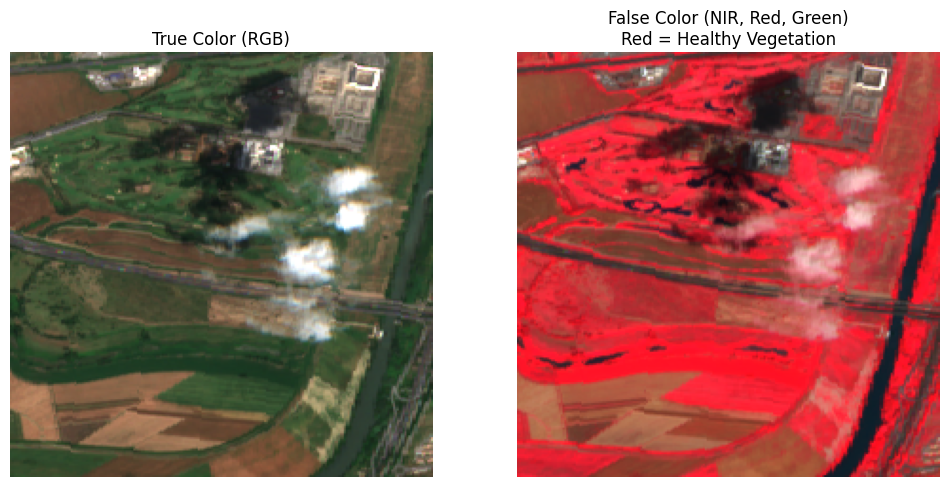

In [ ]:
# TEST INIZIALI

# define regions of interest
rois = [
    ee.Geometry.Rectangle([12.4, 41.8, 12.42, 41.82])   # Rome
    # ee.Geometry.Rectangle([2.3, 48.8, 2.32, 48.82]),  # Paris
    # ... add 100 more regions
]
# stream
dataset = Sentinel2Stream(rois, '2024-06-01', '2024-07-01')
# create dataLoader
loader = DataLoader(dataset, batch_size=2)


# do stuff
for batch_idx, batch in enumerate(loader):
  if batch_idx >= 1:  # check 1 batch (2 images)
    break

  # batch: [batch_size, Channels, H, W]
  print(f"\n--- Batch {batch_idx} ---")
  print(f"Batch tensor shape: {batch.shape} (batch_size, Channels, H, W)")

  # Iterate through images in this batch
  for i in range(len(batch)):
    img_tensor = batch[i]     # shape: [10, H, W]
    print(f"\n--- Image {i} Statistics ---")
    print(f"{'Band':<5} | {'Min':<8} | {'Max':<8} | {'Mean':<8} | {'Std':<8}")
    print("-" * 50)

    # print stats for all bands
    for b_idx, name in enumerate(dataset.bands_to_use):
      band_pixels = img_tensor[b_idx]
      print(f"{name:<5} | {band_pixels.min():.4f}   | {band_pixels.max():.4f}   | {band_pixels.mean():.4f}   | {band_pixels.std():.4f}")

    # --- PLOTTING ---
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    # True Color (Red=B4, Green=B3, Blue=B2) -> Indices 2, 1, 0
    rgb = img_tensor[[2, 1, 0], :, :].permute(1, 2, 0).numpy()
    rgb = np.clip(rgb * 3.0, 0, 1)    # brighten 3x

    ax[0].imshow(rgb)
    ax[0].set_title("True Color (RGB)")
    ax[0].axis('off')

    # False Color Infrared (NIR=B8, Red=B4, Green=B3) -> Indices 6, 2, 1
    # In this view, healthy vegetation appears BRIGHT RED
    fcc = img_tensor[[6, 2, 1], :, :].permute(1, 2, 0).numpy()
    fcc = np.clip(fcc * 2.0, 0, 1) # Brighten 2x

    ax[1].imshow(fcc)
    ax[1].set_title("False Color (NIR, Red, Green)\nRed = Healthy Vegetation")
    ax[1].axis('off')
    plt.show()